# Multi-year and multi-state validation

The screening model in `notebook.ipynb` was trained on one cleaned extract of the CDC
Behavioral Risk Factor Surveillance System (BRFSS). This notebook checks whether it still
works on later survey years and across US states.

**Steps**
1. Rebuild the same 21 features from the raw BRFSS annual files (`scripts/build_multiyear.py`).
2. Check that the rebuilt 2015 file reproduces `data/diabetes.csv`.
3. Track diabetes prevalence by year.
4. Temporal validation: score the saved `models/full_model.joblib` on every later year.
5. Compare actual and predicted prevalence per state and year.
6. Write `models/multiyear.json` and `models/state_prevalence.csv` for the app.

Rebuild the input files first (about 10 minutes, downloads not included):
`python scripts/build_multiyear.py`

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import json, time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, recall_score, precision_score, brier_score_loss

T0 = time.time()
ROOT = Path.cwd()
BRFSS = ROOT / "data" / "brfss"
MODELS, REPORTS = ROOT / "models", ROOT / "reports"
meta = json.loads((MODELS / "meta.json").read_text())
FEATURES, THRESHOLD = meta["features_full"], meta["threshold_full"]
model = joblib.load(MODELS / "full_model.joblib")

# Chart styling: one blue for the main series, orange for the comparison, gray ink.
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "lines.linewidth": 2, "font.size": 10})
print("threshold_full =", round(THRESHOLD, 4))

threshold_full = 0.1475


## 1. Which years can be rebuilt

BRFSS has a fixed core asked every year and a *rotating core* asked every other year.
Blood pressure, cholesterol, and fruit and vegetable intake sit in the rotating core, so
even years (2016, 2018, 2020, 2022, 2024) do not have all 21 features. In 2023 the fruit and
vegetable questions were also not asked. Those years are skipped rather than imputed.

The table shows the raw variable that fed each feature in each year.

In [2]:
src = json.loads((BRFSS / "source_vars.json").read_text())
mapping = pd.DataFrame({int(y): {f: (v or "not asked") for f, v in info["source_vars"].items()}
                        for y, info in sorted(src.items())})
YEARS = sorted(int(y) for y, i in src.items() if i["status"] == "ok")
SKIPPED = {int(y): ("not asked: " + ", ".join(i["missing"])) if i.get("missing") else i.get("reason", "")
           for y, i in sorted(src.items()) if i["status"] != "ok"}
print("Years with all 21 features:", YEARS)
for y, why in SKIPPED.items():
    print(f"  skipped {y}: {why}")
mapping

Years with all 21 features: [2015, 2017, 2019, 2021, 2025]
  skipped 2016: not asked: HighBP, HighChol, CholCheck, Fruits, Veggies
  skipped 2018: not asked: HighBP, HighChol, CholCheck, Fruits, Veggies
  skipped 2020: not asked: HighBP, HighChol, CholCheck, Fruits, Veggies
  skipped 2022: not asked: HighBP, HighChol, CholCheck, Fruits, Veggies
  skipped 2023: not asked: Fruits, Veggies
  skipped 2024: not asked: HighBP, HighChol, CholCheck, Fruits, Veggies


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
HighBP,_RFHYPE5,not asked,_RFHYPE5,not asked,_RFHYPE5,not asked,_RFHYPE6,not asked,_RFHYPE6,not asked,_RFHYPE6
HighChol,TOLDHI2,not asked,TOLDHI2,not asked,TOLDHI2,not asked,TOLDHI3,not asked,TOLDHI3,not asked,TOLDHI3
CholCheck,_CHOLCHK,not asked,_CHOLCH1,not asked,_CHOLCH2,not asked,_CHOLCH3,not asked,_CHOLCH3,not asked,_CHOLCH3
BMI,_BMI5,_BMI5,_BMI5,_BMI5,_BMI5,_BMI5,_BMI5,_BMI5,_BMI5,_BMI5,_BMI5
Smoker,SMOKE100,SMOKE100,SMOKE100,SMOKE100,SMOKE100,SMOKE100,SMOKE100,SMOKE100,SMOKE100,SMOKE100,SMOKE100
Stroke,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3,CVDSTRK3
HeartDiseaseorAttack,_MICHD,_MICHD,_MICHD,_MICHD,_MICHD,_MICHD,_MICHD,_MICHD,_MICHD,_MICHD,_MICHD
PhysActivity,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA,_TOTINDA
Fruits,_FRTLT1,not asked,_FRTLT1A,not asked,_FRTLT1A,not asked,_FRTLT1A,not asked,not asked,not asked,_FRTLT1A
Veggies,_VEGLT1,not asked,_VEGLT1A,not asked,_VEGLT1A,not asked,_VEGLT1A,not asked,not asked,not asked,_VEGLT1A


**Recoding rules** (the same as the Kaggle "CDC Diabetes Health Indicators" cleaning):

- Yes/no questions: 1 = yes, 2 = no. Refused (7), don't know (7/9) and blank are dropped.
- Calculated risk flags (`_RFHYPE*`, `_RFDRHV*`) use 1 = no, 2 = yes and are flipped.
- `CholCheck` = 1 only if cholesterol was checked within 5 years.
- `BMI` = `_BMI5 / 100`, rounded to a whole number.
- `MentHlth`, `PhysHlth`: 88 (none) becomes 0. 77 and 99 are dropped.
- `Income`: `INCOME3` (2021 onward) splits "$75,000 or more" into four levels (8 to 11).
  They are folded back into level 8 so the scale matches the training data.
- Target `Diabetes_binary`: 1 = told they have diabetes. No, prediabetes, and diabetes
  only during pregnancy are 0. Refused and don't know are dropped.
- Any row with a missing value is dropped. `_STATE` (FIPS code) and `year` are kept.

In [3]:
data = {y: pd.read_parquet(BRFSS / f"brfss_{y}.parquet") for y in YEARS}
pd.DataFrame({y: {"raw rows": src[str(y)]["n_raw"], "clean rows": len(d),
                  "kept %": round(100 * len(d) / src[str(y)]["n_raw"], 1)} for y, d in data.items()}).T

,raw rows,clean rows,kept %
2015,441456.0,253680.0,57.5
2017,450016.0,275854.0,61.3
2019,418268.0,243317.0,58.2
2021,438693.0,236378.0,53.9
2025,356158.0,201093.0,56.5


## 2. Sanity check: rebuilt 2015 vs `data/diabetes.csv`

If the cleaning logic is right, the 2015 rebuild should match the training file.

In [4]:
orig = pd.read_csv(ROOT / "data" / "diabetes.csv")
b15 = data[2015][orig.columns]
cmp = pd.DataFrame({"rebuilt 2015 mean": b15.mean(), "diabetes.csv mean": orig.mean()})
cmp["difference"] = cmp.iloc[:, 0] - cmp.iloc[:, 1]
cols = list(orig.columns)
identical = b15.sort_values(cols).reset_index(drop=True).equals(
    orig.astype("int16").sort_values(cols).reset_index(drop=True))
print(f"rows: rebuilt {len(b15):,} vs original {len(orig):,}")
print(f"prevalence: rebuilt {b15.Diabetes_binary.mean():.4f} vs original {orig.Diabetes_binary.mean():.4f}")
print("same multiset of rows:", identical)
assert len(b15) == len(orig) and identical
cmp.round(4)

rows: rebuilt 253,680 vs original 253,680
prevalence: rebuilt 0.1393 vs original 0.1393
same multiset of rows: True


,rebuilt 2015 mean,diabetes.csv mean,difference
HighBP,0.4290,0.4290,0.0
HighChol,0.4241,0.4241,0.0
CholCheck,0.9627,0.9627,0.0
BMI,28.3824,28.3824,0.0
Smoker,0.4432,0.4432,0.0
Stroke,0.0406,0.0406,0.0
HeartDiseaseorAttack,0.0942,0.0942,0.0
PhysActivity,0.7565,0.7565,0.0
Fruits,0.6343,0.6343,0.0
Veggies,0.8114,0.8114,0.0


The rebuilt 2015 file contains exactly the same 253,680 rows as `data/diabetes.csv`. So the
training data is the BRFSS **2015** survey, and its positive class is diagnosed diabetes only
(prediabetes is coded 0, even though the dataset description says otherwise). Every later
year below uses the identical recipe.

Because the model was trained on (most of) these 2015 rows, the 2015 scores below are
in-sample and are shown only as a reference.

## 3. Prevalence by year

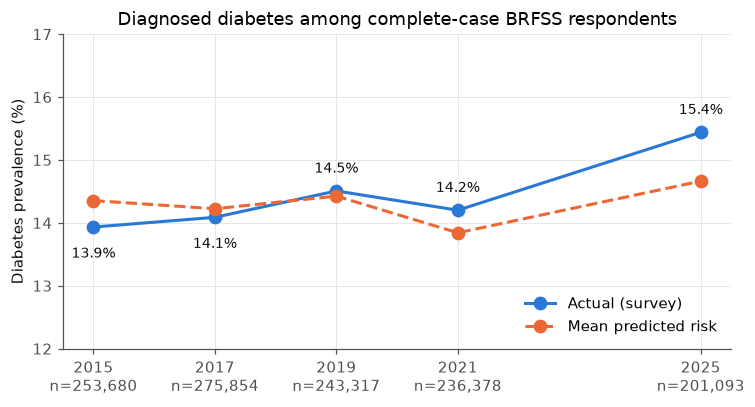

,year,n,actual_rate,mean_predicted
0,2015,253680,0.1393,0.1435
1,2017,275854,0.1409,0.1422
2,2019,243317,0.1451,0.1443
3,2021,236378,0.1420,0.1384
4,2025,201093,0.1544,0.1466


In [5]:
for y, d in data.items():
    d["p"] = model.predict_proba(d[FEATURES].astype("int64"))[:, 1].astype("float32")

prev = pd.DataFrame({"year": YEARS,
                     "n": [len(data[y]) for y in YEARS],
                     "actual_rate": [data[y].Diabetes_binary.mean() for y in YEARS],
                     "mean_predicted": [data[y].p.mean() for y in YEARS]})

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(prev.year, prev.actual_rate * 100, "-o", color=BLUE, ms=8, label="Actual (survey)")
ax.plot(prev.year, prev.mean_predicted * 100, "--o", color=ORANGE, ms=8, label="Mean predicted risk")
for _, r in prev.iterrows():
    ax.annotate(f"{r.actual_rate:.1%}", (r.year, r.actual_rate * 100),
                textcoords="offset points", xytext=(0, -20 if r.mean_predicted > r.actual_rate else 12),
                ha="center", fontsize=9, color=INK)
ax.set_xticks(prev.year, [f"{y}\nn={n:,}" for y, n in zip(prev.year, prev.n)])
ax.set(ylabel="Diabetes prevalence (%)",
       title="Diagnosed diabetes among complete-case BRFSS respondents")
ax.set_ylim(12, 17)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(REPORTS / "multiyear_prevalence.png", bbox_inches="tight"); plt.show()
prev.round(4)

## 4. Temporal validation of the saved model

The saved model was trained once, on the 2015 extract. Here it scores each later year
with no retraining. Metrics use `threshold_full` from `meta.json`.

In [6]:
def scores(y, p):
    pred = p >= THRESHOLD
    return {"roc_auc": roc_auc_score(y, p), "recall": recall_score(y, pred),
            "precision": precision_score(y, pred), "brier": brier_score_loss(y, p), "n": len(y)}

tv = pd.DataFrame([{"train_years": "BRFSS 2015", "test_year": y,
                    **scores(data[y].Diabetes_binary, data[y].p)} for y in YEARS])
tv["note"] = np.where(tv.test_year == 2015, "in-sample reference", "out-of-time")
tv.round(4)

,train_years,test_year,roc_auc,recall,precision,brier,n,note
0,BRFSS 2015,2015,0.8317,0.7937,0.3087,0.0963,253680,in-sample reference
1,BRFSS 2015,2017,0.8305,0.7888,0.3130,0.0973,275854,out-of-time
2,BRFSS 2015,2019,0.8242,0.7811,0.3146,0.1004,243317,out-of-time
3,BRFSS 2015,2021,0.8185,0.7603,0.3118,0.1000,236378,out-of-time
4,BRFSS 2015,2025,0.8033,0.7613,0.3141,0.1092,201093,out-of-time


### Optional comparison: retrain on newer data

Is any drop caused by drift? To check, clone the saved model's exact pipeline and refit it
on 2015, 2017 and 2019 (deduplicated, 300,000-row sample to fit in memory). Then score
2021 and 2025 again. If the retrained model is not much better, the original model is still fit
for purpose.

In [7]:
train = pd.concat([data[y][FEATURES + ["Diabetes_binary"]] for y in YEARS if y <= 2019]).drop_duplicates()
train = train.sample(min(300_000, len(train)), random_state=42)
t = time.time()
retrained = clone(model).fit(train[FEATURES].astype("int64"), train.Diabetes_binary)
print(f"retrained on {len(train):,} rows in {time.time() - t:.0f}s")
del train

rt = []
for y in [y for y in YEARS if y >= 2021]:
    p_new = retrained.predict_proba(data[y][FEATURES].astype("int64"))[:, 1]
    rt.append({"train_years": "2015-2019 (retrained, odd years)", "test_year": y,
               **scores(data[y].Diabetes_binary, p_new)})
rt = pd.DataFrame(rt)
pd.concat([tv[tv.test_year >= 2021].drop(columns="note"), rt]).sort_values("test_year").round(4)

retrained on 300,000 rows in 12s


,train_years,test_year,roc_auc,recall,precision,brier,n
3,BRFSS 2015,2021,0.8185,0.7603,0.3118,0.1000,236378
0,"2015-2019 (retrained, odd years)",2021,0.8183,0.7897,0.2999,0.1000,236378
4,BRFSS 2015,2025,0.8033,0.7613,0.3141,0.1092,201093
1,"2015-2019 (retrained, odd years)",2025,0.8037,0.7948,0.3034,0.1091,201093


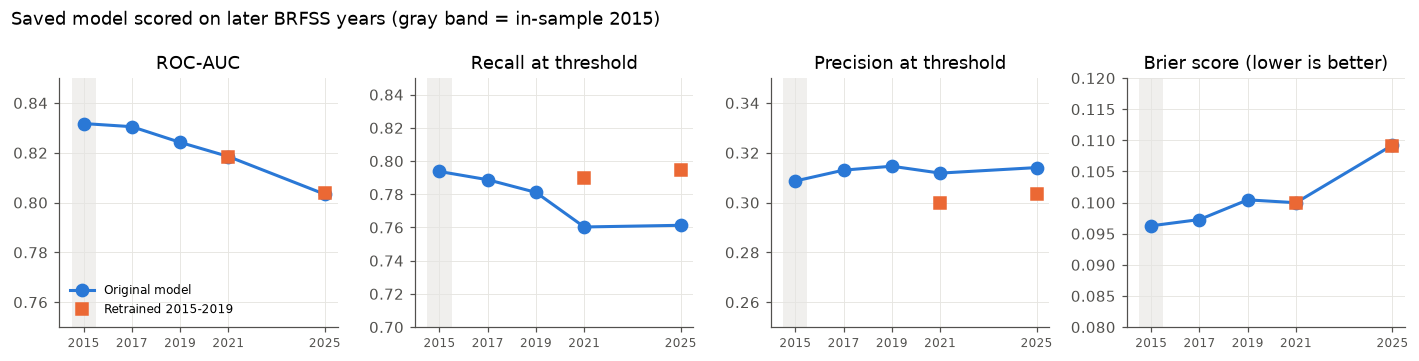

In [8]:
metrics = [("roc_auc", "ROC-AUC", (0.75, 0.85)), ("recall", "Recall at threshold", (0.70, 0.85)),
           ("precision", "Precision at threshold", (0.25, 0.35)), ("brier", "Brier score (lower is better)", (0.08, 0.12))]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, (m, label, ylim) in zip(axes, metrics):
    ax.plot(tv.test_year, tv[m], "-o", color=BLUE, ms=8, label="Original model")
    ax.plot(rt.test_year, rt[m], "s", color=ORANGE, ms=8, label="Retrained 2015-2019")
    ax.axvspan(2014.5, 2015.5, color="#e6e5e1", alpha=0.6, lw=0)
    ax.set(title=label, xticks=tv.test_year, ylim=ylim)
    ax.tick_params(axis="x", labelsize=8)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Saved model scored on later BRFSS years (gray band = in-sample 2015)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(REPORTS / "multiyear_temporal.png", bbox_inches="tight"); plt.show()

### Feature drift

Mean of each feature per year, minus its 2015 mean, in units of the 2015 standard
deviation. Values near 0 mean the population looks like the training data.

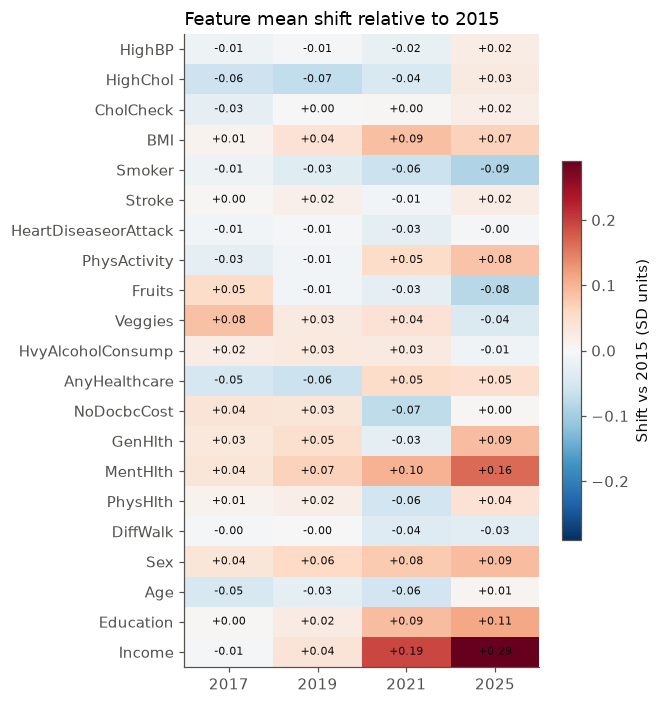

In [9]:
base = data[2015][FEATURES]
drift = pd.DataFrame({y: (data[y][FEATURES].mean() - base.mean()) / base.std() for y in YEARS if y != 2015})
fig, ax = plt.subplots(figsize=(6, 6.5))
lim = max(0.1, float(np.abs(drift.values).max()))
im = ax.imshow(drift.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set(xticks=range(drift.shape[1]), xticklabels=drift.columns, yticks=range(len(FEATURES)), yticklabels=FEATURES)
ax.grid(False)
for i in range(drift.shape[0]):
    for j in range(drift.shape[1]):
        ax.text(j, i, f"{drift.iat[i, j]:+.2f}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, ax=ax, shrink=0.6, label="Shift vs 2015 (SD units)")
ax.set_title("Feature mean shift relative to 2015", loc="left")
fig.tight_layout(); fig.savefig(REPORTS / "multiyear_drift.png", bbox_inches="tight"); plt.show()

## 5. Actual vs predicted prevalence by state

For each state and year: the share of respondents with diagnosed diabetes, and the mean
predicted risk. States with fewer than 500 complete-case respondents in a year are marked
**low confidence**. Territories (Guam, Puerto Rico, Virgin Islands) are dropped. Rates are
unweighted sample rates, not official weighted state estimates.

**Missing state-years.** A few states have no rows in some years: New Jersey (2019), Florida
(2021), and California, Mississippi and Nevada (2025). They are absent from CDC's public file
itself (0 raw records), so our recoding did not drop them. CDC's annual overview for each year
says the state could not collect enough data to meet the minimum requirements for inclusion
in that year's aggregate data set. They are listed in `missing_states` in `models/multiyear.json`.

In [10]:
STATES = {1: ("AL", "Alabama"), 2: ("AK", "Alaska"), 4: ("AZ", "Arizona"), 5: ("AR", "Arkansas"),
    6: ("CA", "California"), 8: ("CO", "Colorado"), 9: ("CT", "Connecticut"), 10: ("DE", "Delaware"),
    11: ("DC", "District of Columbia"), 12: ("FL", "Florida"), 13: ("GA", "Georgia"), 15: ("HI", "Hawaii"),
    16: ("ID", "Idaho"), 17: ("IL", "Illinois"), 18: ("IN", "Indiana"), 19: ("IA", "Iowa"),
    20: ("KS", "Kansas"), 21: ("KY", "Kentucky"), 22: ("LA", "Louisiana"), 23: ("ME", "Maine"),
    24: ("MD", "Maryland"), 25: ("MA", "Massachusetts"), 26: ("MI", "Michigan"), 27: ("MN", "Minnesota"),
    28: ("MS", "Mississippi"), 29: ("MO", "Missouri"), 30: ("MT", "Montana"), 31: ("NE", "Nebraska"),
    32: ("NV", "Nevada"), 33: ("NH", "New Hampshire"), 34: ("NJ", "New Jersey"), 35: ("NM", "New Mexico"),
    36: ("NY", "New York"), 37: ("NC", "North Carolina"), 38: ("ND", "North Dakota"), 39: ("OH", "Ohio"),
    40: ("OK", "Oklahoma"), 41: ("OR", "Oregon"), 42: ("PA", "Pennsylvania"), 44: ("RI", "Rhode Island"),
    45: ("SC", "South Carolina"), 46: ("SD", "South Dakota"), 47: ("TN", "Tennessee"), 48: ("TX", "Texas"),
    49: ("UT", "Utah"), 50: ("VT", "Vermont"), 51: ("VA", "Virginia"), 53: ("WA", "Washington"),
    54: ("WV", "West Virginia"), 55: ("WI", "Wisconsin"), 56: ("WY", "Wyoming")}
assert len(STATES) == 51

rows = []
for y, d in data.items():
    g = d.groupby("_STATE").agg(n=("p", "size"), actual_rate=("Diabetes_binary", "mean"), predicted_rate=("p", "mean"))
    g = g[g.index.isin(STATES)]
    g.insert(0, "year", y)
    g.insert(0, "state_name", [STATES[s][1] for s in g.index])
    g.insert(0, "state_abbr", [STATES[s][0] for s in g.index])
    rows.append(g.reset_index(drop=True))
state = pd.concat(rows, ignore_index=True)
state["low_confidence"] = state.n < 500
state["gap"] = state.predicted_rate - state.actual_rate
print("state-years:", len(state), "| low confidence:", int(state.low_confidence.sum()))
MISSING = {y: sorted(set(v[0] for v in STATES.values()) - set(state[state.year == y].state_abbr)) for y in YEARS}
MISSING = {y: s for y, s in MISSING.items() if s}
print("states missing per year:", MISSING)
# Reasons quoted in substance from CDC's annual BRFSS overview documents (checked 0 raw records for each)
CDC_REASON = {
    (2019, "NJ"): "Not in CDC's 2019 public file: New Jersey could not collect enough BRFSS data to meet the minimum requirements for inclusion (CDC 2019 overview).",
    (2021, "FL"): "Not in CDC's 2021 public file: Florida could not collect BRFSS data over enough months to meet the minimum requirements for inclusion (CDC 2021 overview).",
    (2025, "CA"): "Not in CDC's 2025 public file: California could not collect enough data to meet the minimum requirements for inclusion (CDC 2025 annual data page).",
    (2025, "MS"): "Not in CDC's 2025 public file: Mississippi could not collect enough data to meet the minimum requirements for inclusion (CDC 2025 annual data page).",
    (2025, "NV"): "Not in CDC's 2025 public file: Nevada could not collect enough data to meet the minimum requirements for inclusion (CDC 2025 annual data page).",
}
assert set(CDC_REASON) == {(y, s) for y, ss in MISSING.items() for s in ss}, "missing states changed; update CDC_REASON"
print(f"mean absolute gap (predicted - actual): {state.gap.abs().mean():.4f}")
print(f"correlation actual vs predicted: {state.actual_rate.corr(state.predicted_rate):.3f}")
state.sort_values("gap").groupby("year").head(2).round(4)

state-years: 250 | low confidence: 0
states missing per year: {2019: ['NJ'], 2021: ['FL'], 2025: ['CA', 'MS', 'NV']}
mean absolute gap (predicted - actual): 0.0099
correlation actual vs predicted: 0.917


,state_abbr,state_name,year,n,actual_rate,predicted_rate,low_confidence,gap
219,LA,Louisiana,2025,2690,0.2145,0.1684,False,-0.0461
239,SC,South Carolina,2025,2161,0.2166,0.1737,False,-0.0428
193,TN,Tennessee,2021,2587,0.1805,0.1501,False,-0.0304
161,GA,Georgia,2021,4074,0.1905,0.1622,False,-0.0283
102,AL,Alabama,2019,4142,0.1936,0.1718,False,-0.0218
112,GA,Georgia,2019,3791,0.1791,0.1587,False,-0.0204
91,SC,South Carolina,2017,6803,0.1871,0.1691,False,-0.0180
94,TX,Texas,2017,7507,0.1760,0.1580,False,-0.0180
24,MS,Mississippi,2015,3442,0.2103,0.1947,False,-0.0156
0,AL,Alabama,2015,4401,0.1913,0.1776,False,-0.0137


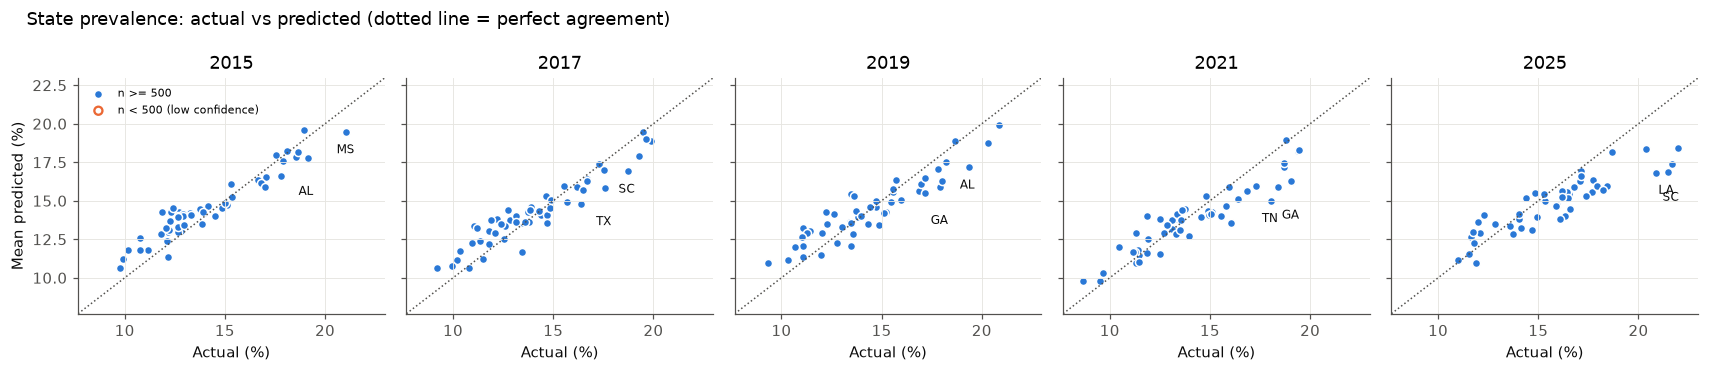

In [11]:
fig, axes = plt.subplots(1, len(YEARS), figsize=(3.1 * len(YEARS), 3.4), sharex=True, sharey=True)
lo, hi = state[["actual_rate", "predicted_rate"]].min().min() * 100 - 1, state[["actual_rate", "predicted_rate"]].max().max() * 100 + 1
for ax, y in zip(axes, YEARS):
    s = state[state.year == y]
    ok, low = s[~s.low_confidence], s[s.low_confidence]
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls=":")
    ax.scatter(ok.actual_rate * 100, ok.predicted_rate * 100, s=28, color=BLUE, edgecolor="white", lw=1, label="n >= 500")
    ax.scatter(low.actual_rate * 100, low.predicted_rate * 100, s=28, facecolor="none", edgecolor=ORANGE, lw=1.5, label="n < 500 (low confidence)")
    for k, (_, r) in enumerate(s.nsmallest(2, "gap").iterrows()):  # two largest under-predictions
        ax.annotate(r.state_abbr, (r.actual_rate * 100, r.predicted_rate * 100), xytext=(-6, -14 - 10 * k),
                    textcoords="offset points", fontsize=8, color=INK)
    ax.set(title=str(y), xlim=(lo, hi), ylim=(lo, hi), xlabel="Actual (%)")
axes[0].set_ylabel("Mean predicted (%)")
axes[0].legend(frameon=False, fontsize=7, loc="upper left")
fig.suptitle("State prevalence: actual vs predicted (dotted line = perfect agreement)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(REPORTS / "multiyear_states.png", bbox_inches="tight"); plt.show()

## 6. Artifacts for the app

In [12]:
out = {
    "years": YEARS,
    "prevalence_by_year": [{"year": int(r.year), "rate": round(float(r.actual_rate), 5), "n": int(r.n)}
                           for r in prev.itertuples()],
    "temporal_validation": [
        {"train_years": r.train_years, "test_year": int(r.test_year), "roc_auc": round(r.roc_auc, 4),
         "recall": round(r.recall, 4), "precision": round(r.precision, 4), "brier": round(r.brier, 4), "n": int(r.n)}
        for r in pd.concat([tv[tv.test_year != 2015], rt]).itertuples()],
    "total_rows": int(prev.n.sum()),
    "skipped_years": sorted(SKIPPED),
    "skipped_reasons": {str(k): v for k, v in SKIPPED.items()},
    "missing_states": {str(y): [{"state": s, "reason": CDC_REASON[(y, s)]} for s in ss] for y, ss in MISSING.items()},
}
(MODELS / "multiyear.json").write_text(json.dumps(out, indent=1))
cols = ["state_abbr", "state_name", "year", "n", "actual_rate", "predicted_rate"]
state[cols].round(5).to_csv(MODELS / "state_prevalence.csv", index=False)

# self-check of the contract the app codes against
chk = json.loads((MODELS / "multiyear.json").read_text())
assert {"years", "prevalence_by_year", "temporal_validation", "total_rows", "skipped_years"} <= set(chk)
assert all(set(r) == {"year", "rate", "n"} for r in chk["prevalence_by_year"])
assert all(set(r) == {"train_years", "test_year", "roc_auc", "recall", "precision", "brier", "n"} for r in chk["temporal_validation"])
sp = pd.read_csv(MODELS / "state_prevalence.csv")
assert list(sp.columns) == cols and sp.state_abbr.nunique() <= 51 and sp.actual_rate.between(0, 1).all()
for f in ["multiyear.json", "state_prevalence.csv"]:
    print(f, f"{(MODELS / f).stat().st_size / 1024:.1f} KB")
print(f"total rows {chk['total_rows']:,} | runtime {time.time() - T0:.0f}s")

multiyear.json 3.1 KB
state_prevalence.csv 9.7 KB
total rows 1,210,322 | runtime 37s


## 7. Insights and limitations

**Insights**

1. **The model holds up over a decade.** ROC-AUC goes from 0.832 on (in-sample) 2015 to
   0.830 (2017), 0.824 (2019), 0.819 (2021) and 0.803 (2025). That is a slow decline of about
   0.003 per year, with no retraining.
2. **Recall slips below the 0.80 target after 2019.** At the saved threshold, recall is 0.76 in
   2021 and 2025, while precision stays near 0.31. Prevalence rose to 15.4% in 2025 and the model
   under-predicts it (mean risk 14.7%). Lowering the threshold, or recalibrating on recent data,
   would restore recall.
3. **More data from 2015-2019 does not fix the decline.** The same pipeline refit on 2015, 2017
   and 2019 has the same ROC-AUC on 2021 (0.818 vs 0.819) and 2025 (0.804 vs 0.803). Its higher
   recall comes from where its threshold falls, at the cost of precision. So the drop comes from
   a changing population, not just an old training year.
4. **Income shows the largest drift**: +0.19 SD in 2021 and +0.29 SD in 2025. The brackets are in
   nominal dollars and have not changed since 2015, so inflation pushes more people into
   "$75,000 or more". The 2021 `INCOME3` split of that bracket is folded back so the scale matches,
   but its meaning still shifts. Poor mental health days (+0.16 SD) and education (+0.11 SD) also
   rose by 2025.
5. **State estimates track well but miss the high-prevalence South.** Across 250 state-years,
   actual and predicted state rates correlate at 0.92 and differ by 1.0 percentage point on
   average. The largest misses are under-predictions: Louisiana and South Carolina in 2025 (about
   4 points), Tennessee and Georgia in 2021. The model has no geography, race or ethnicity inputs.

**Limitations**

- **Only odd years can be checked.** Blood pressure, cholesterol and fruit and vegetable questions
  are in the BRFSS rotating core, so 2016, 2018, 2020, 2022 and 2024 lack features. 2023 also
  omitted the fruit and vegetable questions.
- **2020 COVID disruption.** The pandemic changed BRFSS collection in 2020: fewer interviews in some
  months and states, and a shift in who answered. 2020 is an even year and cannot be scored here.
  2021, the first year after, has the lowest complete-case share (53.9%).
- **Complete cases only.** Dropping any row with a missing answer removes 39% to 46% of respondents
  each year. That can bias prevalence: income is the most-refused item.
- **Unweighted rates.** State and year rates are sample rates, not CDC weighted estimates, so they
  will differ from official figures. Some states are missing from a public file: New Jersey (2019),
  Florida (2021), and California, Mississippi and Nevada (2025).
- **The target is diagnosed diabetes.** Undiagnosed diabetes is invisible to a self-report survey.
  Prediabetes is coded 0, which matches the training data even though the dataset description says
  otherwise.